In [1]:
import os
import gc
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [2]:
# ============================================================
# Paths
# ============================================================

RESULTS_DIR = "../results/mediation"

os.makedirs(RESULTS_DIR, exist_ok=True)

X_TRAIN_PATH = "../data_processed/x_train_nb_sample.csv"

# Causal/PFA file created from PCP count-model causal preparation
PFA_CAUSAL_PATH = "../results/poisson_intensity_sample/pcp_count_individual_sdoh_poisson_causal_dat_nsdoh_pfa_full.csv"

In [3]:
pfa_df = pd.read_csv(PFA_CAUSAL_PATH)

print("PFA dataframe shape:", pfa_df.shape)
print("\nColumns:")
for i, c in enumerate(pfa_df.columns):
    print(i, c)

pfa_df.head()

PFA dataframe shape: (1476720, 20)

Columns:
0 pcp_count_log
1 pcp_count_nSDoH_pfa_score
2 age_65_group
3 Member_Has_HTN_Diag_Ind
4 Member_Has_Other_Mental_Health_Diag_Ind
5 Member_Has_Anxiety_Disorders_Diag_Ind
6 Member_Has_Diabetes_Diag_Ind
7 Member_Has_Asthma_Diag_Ind
8 Race_White
9 Member_Has_Osteoarthritis_Diag_Ind
10 Member_Marital_Status_Current_Single
11 Product_Type_PPO
12 Member_Has_Liver_Disease_Diag_Ind
13 Member_Gender_Current_Female
14 Product_Type_POS
15 Member_Has_COPD_Diag_Ind
16 Member_Has_Depression_Diag_Ind
17 Member_Marital_Status_Current_Married
18 Member_Has_Burns_Diag_Ind
19 Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind


,pcp_count_log,pcp_count_nSDoH_pfa_score,age_65_group,Member_Has_HTN_Diag_Ind,Member_Has_Other_Mental_Health_Diag_Ind,Member_Has_Anxiety_Disorders_Diag_Ind,Member_Has_Diabetes_Diag_Ind,Member_Has_Asthma_Diag_Ind,Race_White,Member_Has_Osteoarthritis_Diag_Ind,Member_Marital_Status_Current_Single,Product_Type_PPO,Member_Has_Liver_Disease_Diag_Ind,Member_Gender_Current_Female,Product_Type_POS,Member_Has_COPD_Diag_Ind,Member_Has_Depression_Diag_Ind,Member_Marital_Status_Current_Married,Member_Has_Burns_Diag_Ind,Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind
0,0.0,-0.185024,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
1,0.0,0.688136,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,0.0,-2.190125,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0
3,0.0,-2.150534,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0
4,0.0,0.879615,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


# Mediator Model

In [4]:
# ============================================================
# Mediation setup: PCP count model
# ============================================================

PFA_SCORE_COL = "pcp_count_nSDoH_pfa_score"

EXPOSURE_COL = "high_nsdoh_85"

MEDIATOR_COL = "Member_Has_HTN_Diag_Ind"

AGE_COL = "age_65_group"
SEX_COL = "Member_Gender_Current_Female"
RACE_COL = "Race_White"

In [5]:
# ============================================================
# Comorbidity columns excluding hypertension
# ============================================================

comorbidity_cols_no_htn = [
    "Member_Has_Other_Mental_Health_Diag_Ind",
    "Member_Has_Anxiety_Disorders_Diag_Ind",
    "Member_Has_Diabetes_Diag_Ind",
    "Member_Has_Asthma_Diag_Ind",
    "Member_Has_Osteoarthritis_Diag_Ind",
    "Member_Has_Liver_Disease_Diag_Ind",
    "Member_Has_COPD_Diag_Ind",
    "Member_Has_Depression_Diag_Ind",
    "Member_Has_Burns_Diag_Ind",
    "Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind"
]

comorbidity_cols_no_htn = [
    c for c in comorbidity_cols_no_htn
    if c in pfa_df.columns
]

print("Comorbidity columns used, excluding HTN:")
print(comorbidity_cols_no_htn)

Comorbidity columns used, excluding HTN:
['Member_Has_Other_Mental_Health_Diag_Ind', 'Member_Has_Anxiety_Disorders_Diag_Ind', 'Member_Has_Diabetes_Diag_Ind', 'Member_Has_Asthma_Diag_Ind', 'Member_Has_Osteoarthritis_Diag_Ind', 'Member_Has_Liver_Disease_Diag_Ind', 'Member_Has_COPD_Diag_Ind', 'Member_Has_Depression_Diag_Ind', 'Member_Has_Burns_Diag_Ind', 'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind']


In [6]:
# ============================================================
# Full comorbidity list for burden calculation
# Exclude HTN because HTN is the mediator
# ============================================================

full_com_list = [
    'Member_Has_ALS_Diag_Ind',
    'Member_Has_AMI_Diag_Ind',
    'Member_Has_Anxiety_Disorders_Diag_Ind',
    'Member_Has_Asthma_Diag_Ind',
    'Member_Has_Burns_Diag_Ind',
    'Member_Has_Cancer_Diag_Ind',
    'Member_Has_Cardiac_Congenital_Anomalies_Diag_Ind',
    'Member_Has_CHF_Diag_Ind',
    'Member_Has_CAD_Diag_Ind',
    'Member_Has_Cerobrovascular_Disease_Diag_Ind',
    'Member_Has_CIDP_Diag_Ind',
    'Member_Has_CKD_Diag_Ind',
    'Member_Has_Congenital_Hydrocephalus_Diag_Ind',
    'Member_Has_Connective_Tissue_Disorder_Diag_Ind',
    'Member_Has_COPD_Diag_Ind',
    'Member_Has_Crohns_Diag_Ind',
    'Member_Has_Cystic_Fibrosis_Diag_Ind',
    'Member_Has_Depression_Diag_Ind',
    'Member_Has_Dermatomyositis_Diag_Ind',
    'Member_Has_Diabetes_Diag_Ind',
    'Member_Has_Epilepsy_Diag_Ind',
    'Member_Has_ESRD_Diag_Ind',
    'Member_Has_Gaucher_Disease_Diag_Ind',
    'Member_Has_Hemophilia_Diag_Ind',
    'Member_Has_Hepatitis_Diag_Ind',
    'Member_Has_HIV_Diag_Ind',
    'Member_Has_HTN_Diag_Ind',
    'Member_Has_Liver_Disease_Diag_Ind',
    'Member_Has_Lupus_Diag_Ind',
    'Member_Has_Multiple_Sclerosis_Diag_Ind',
    'Member_Has_Myasthenia_Gravis_Diag_Ind',
    'Member_Has_Myositis_Diag_Ind',
    'Member_Has_Nephritis_Nephrosis_or_Sclerosis_Diag_Ind',
    'Member_Has_Osteoarthritis_Diag_Ind',
    'Member_Has_Other_Mental_Health_Diag_Ind',
    'Member_Has_Other_Nerv_Sys_Congenital_Anomalies_Diag_Ind',
    'Member_Has_Parkinsons_Diag_Ind',
    'Member_Has_Peri_Endo_Myocarditis_or_Cardiomyopathy_Diag_Ind',
    'Member_Has_Polymyositis_Diag_Ind',
    'Member_Has_Pulmonary_Heart_Disease_Diag_Ind',
    'Member_Has_RA_Diag_Ind',
    'Member_Has_Resp_Failure_Insuff_Arrest_Diag_Ind',
    'Member_Has_Scleroderma_Diag_Ind',
    'Member_Has_Sickle_Cell_Anemia_Diag_Ind',
    'Member_Has_Spina_Bifida_Diag_Ind',
    'Member_Has_Spinal_Cord_Injury_Diag_Ind',
    'Member_Has_Substance_Abuse_Disorder_Diag_Ind',
    'Member_Has_Ulcerative_Colitis_Diag_Ind'
]

full_comorbidity_cols_no_htn = [
    c for c in full_com_list
    if c != "Member_Has_HTN_Diag_Ind"
]

print("Number of full comorbidity columns excluding HTN:", len(full_comorbidity_cols_no_htn))

Number of full comorbidity columns excluding HTN: 47


In [7]:
# ============================================================
# Load full comorbidity columns from x_train
# ============================================================

x_train_cols = pd.read_csv(X_TRAIN_PATH, nrows=0).columns.tolist()

available_full_comorbidity_cols = [
    c for c in full_comorbidity_cols_no_htn
    if c in x_train_cols
]

missing_full_comorbidity_cols = [
    c for c in full_comorbidity_cols_no_htn
    if c not in x_train_cols
]

print("Available full comorbidity columns:", len(available_full_comorbidity_cols))
print("Missing full comorbidity columns:", len(missing_full_comorbidity_cols))
print(missing_full_comorbidity_cols)

x_full_comorbidity = pd.read_csv(
    X_TRAIN_PATH,
    usecols=available_full_comorbidity_cols
)

print("x_full_comorbidity shape:", x_full_comorbidity.shape)
print("pfa_df shape:", pfa_df.shape)

if len(x_full_comorbidity) != len(pfa_df):
    raise ValueError(
        "Row count mismatch between PFA file and x_train. "
        "Do not join by index unless row counts/order are confirmed."
    )

Available full comorbidity columns: 47
Missing full comorbidity columns: 0
[]
x_full_comorbidity shape: (1476720, 47)
pfa_df shape: (1476720, 20)


In [8]:
# ============================================================
# Create exposure: top 15% nSDoH burden
# ============================================================

nsdoh_threshold_85 = pfa_df[PFA_SCORE_COL].quantile(0.85)

pfa_df[EXPOSURE_COL] = (
    pfa_df[PFA_SCORE_COL] >= nsdoh_threshold_85
).astype(int)

print("nSDoH 85th percentile threshold:", nsdoh_threshold_85)

print("\nExposure counts:")
print(pfa_df[EXPOSURE_COL].value_counts())

print("\nExposure proportions:")
print(pfa_df[EXPOSURE_COL].value_counts(normalize=True))

nSDoH 85th percentile threshold: 1.01183687391069

Exposure counts:
0    1254979
1     221741
Name: high_nsdoh_85, dtype: int64

Exposure proportions:
0    0.849842
1    0.150158
Name: high_nsdoh_85, dtype: float64


In [9]:
# ============================================================
# Build mediator dataframe
# ============================================================

mediation_df = pd.DataFrame()

# Exposure
mediation_df[EXPOSURE_COL] = pfa_df[EXPOSURE_COL].astype(int)

# Mediator: hypertension
mediation_df["hypertension"] = pd.to_numeric(
    pfa_df[MEDIATOR_COL],
    errors="coerce"
)

# Age adjustment
mediation_df["age_65_group"] = pd.to_numeric(
    pfa_df[AGE_COL],
    errors="coerce"
)

# Sex adjustment
mediation_df["female"] = pd.to_numeric(
    pfa_df[SEX_COL],
    errors="coerce"
)

# Race adjustment
mediation_df["race_white"] = pd.to_numeric(
    pfa_df[RACE_COL],
    errors="coerce"
)

# Baseline comorbidity burden excluding hypertension
# mediation_df["baseline_comorbidity_burden_no_htn"] = (
#     pfa_df[comorbidity_cols_no_htn]
#     .apply(pd.to_numeric, errors="coerce")
#     .fillna(0)
#     .sum(axis=1)
# )
# Full baseline comorbidity burden excluding HTN
mediation_df["baseline_comorbidity_burden_no_htn"] = (
    x_full_comorbidity[available_full_comorbidity_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
    .sum(axis=1)
)

print("Full comorbidity burden summary:")
print(mediation_df["baseline_comorbidity_burden_no_htn"].describe())

print("\nFull comorbidity burden counts:")
print(mediation_df["baseline_comorbidity_burden_no_htn"].value_counts().sort_index().head(20))

print("Mediator dataframe shape:", mediation_df.shape)
mediation_df.head()

Full comorbidity burden summary:
count    1.476720e+06
mean     1.855057e-01
std      6.146500e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.400000e+01
Name: baseline_comorbidity_burden_no_htn, dtype: float64

Full comorbidity burden counts:
0     1300798
1      116546
2       37206
3       13275
4        4946
5        2039
6         960
7         526
8         223
9         112
10         52
11         24
12         11
14          2
Name: baseline_comorbidity_burden_no_htn, dtype: int64
Mediator dataframe shape: (1476720, 6)


,high_nsdoh_85,hypertension,age_65_group,female,race_white,baseline_comorbidity_burden_no_htn
0,0,0,0,0,1,0
1,0,0,0,1,0,0
2,0,0,0,1,0,0
3,0,0,0,1,1,0
4,0,0,0,0,0,0


In [42]:
# ============================================================
# Clean mediator dataframe
# ============================================================

mediation_df = mediation_df.replace([np.inf, -np.inf], np.nan)

print("Missing values before drop:")
print(mediation_df.isna().sum())

mediation_df = mediation_df.dropna().copy()

mediation_df[EXPOSURE_COL] = mediation_df[EXPOSURE_COL].astype(int)
mediation_df["hypertension"] = mediation_df["hypertension"].astype(int)

print("Final mediator dataframe shape:", mediation_df.shape)

print("\nExposure distribution:")
print(mediation_df[EXPOSURE_COL].value_counts(normalize=True))

print("\nHypertension distribution:")
print(mediation_df["hypertension"].value_counts(normalize=True))

Missing values before drop:
high_nsdoh_85                         0
hypertension                          0
age_65_group                          0
female                                0
race_white                            0
baseline_comorbidity_burden_no_htn    0
dtype: int64
Final mediator dataframe shape: (1476720, 6)

Exposure distribution:
0    0.849842
1    0.150158
Name: high_nsdoh_85, dtype: float64

Hypertension distribution:
0    0.938763
1    0.061237
Name: hypertension, dtype: float64


In [43]:
# ============================================================
# Mediator model
# Outcome: hypertension
# Model: logistic regression
# ============================================================

mediator_model_features = [
    EXPOSURE_COL,
    "age_65_group",
    "female",
    "race_white",
    "baseline_comorbidity_burden_no_htn"
]

X_mediator = mediation_df[mediator_model_features].astype(float)
X_mediator = sm.add_constant(X_mediator, has_constant="add")

y_mediator = mediation_df["hypertension"].astype(int)

print("X_mediator shape:", X_mediator.shape)
print("Hypertension mean:", y_mediator.mean())

mediator_model = sm.GLM(
    y_mediator,
    X_mediator,
    family=sm.families.Binomial()
)

mediator_result = mediator_model.fit()

print(mediator_result.summary())

X_mediator shape: (1476720, 6)
Hypertension mean: 0.06123706592989869
                 Generalized Linear Model Regression Results                  
Dep. Variable:           hypertension   No. Observations:              1476720
Model:                            GLM   Df Residuals:                  1476714
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -2.4911e+05
Date:                Sat, 18 Jul 2026   Deviance:                   4.9822e+05
Time:                        01:12:26   Pearson chi2:                 1.66e+06
No. Iterations:                     7   Pseudo R-squ. (CS):             0.1160
Covariance Type:            nonrobust                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------

In [44]:
# ============================================================
# Mediator model result table
# ============================================================

mediator_coef_df = pd.DataFrame({
    "feature": mediator_result.params.index,
    "coef_log_odds": mediator_result.params.values,
    "std_error": mediator_result.bse.values,
    "z_score": mediator_result.tvalues.values,
    "pvalue": mediator_result.pvalues.values
})

mediator_coef_df["OR"] = np.exp(mediator_coef_df["coef_log_odds"])

mediator_coef_df["CI_lower"] = np.exp(
    mediator_coef_df["coef_log_odds"] - 1.96 * mediator_coef_df["std_error"]
)

mediator_coef_df["CI_upper"] = np.exp(
    mediator_coef_df["coef_log_odds"] + 1.96 * mediator_coef_df["std_error"]
)

mediator_coef_df = mediator_coef_df.sort_values("pvalue")

mediator_coef_df

,feature,coef_log_odds,std_error,z_score,pvalue,OR,CI_lower,CI_upper
0,const,-3.614952,0.007174,-503.908381,0.000000e+00,0.026918,0.026542,0.027299
2,age_65_group,1.367319,0.009368,145.951066,0.000000e+00,3.924816,3.853406,3.997549
5,baseline_comorbidity_burden_no_htn,1.447683,0.004558,317.579725,0.000000e+00,4.253250,4.215418,4.291421
1,high_nsdoh_85,0.238709,0.010518,22.694691,5.054858e-114,1.269610,1.243703,1.296055
3,female,-0.110796,0.008042,-13.777851,3.464337e-43,0.895121,0.881123,0.909341
4,race_white,-0.009915,0.009072,-1.092994,2.743963e-01,0.990134,0.972685,1.007896


In [32]:
# ============================================================
# Save mediator model results
# ============================================================

mediator_result_path = os.path.join(
    RESULTS_DIR,
    "pcp_count_mediation_mediator_model_hypertension_full_comorbidity_results.csv"
)

mediator_coef_df.to_csv(mediator_result_path, index=False)

print("Saved mediator model results to:", mediator_result_path)

Saved mediator model results to: ../results/mediation/pcp_count_mediation_mediator_model_hypertension_full_comorbidity_results.csv


# Outcome Model

In [45]:
# ============================================================
# Add PCP count outcome
# ============================================================

PCP_LOG_COL = "pcp_count_log"
PCP_COUNT_COL = "pcp_count_observed"
# ER_LOG_COL = "ER_count_log"
# ER_COUNT_COL = "ER_count_observed"

# Recover observed PCP count from log1p(count)
mediation_df[PCP_COUNT_COL] = (
    np.expm1(pfa_df.loc[mediation_df.index, PCP_LOG_COL])
    .round()
    .astype(int)
)

print("PCP count outcome summary:")
print(mediation_df[PCP_COUNT_COL].describe())

print("\nPCP count value counts:")
print(mediation_df[PCP_COUNT_COL].value_counts().sort_index().head(20))

print("\nMean PCP count:", mediation_df[PCP_COUNT_COL].mean())

PCP count outcome summary:
count    1.476720e+06
mean     1.331823e-01
std      4.026833e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.300000e+01
Name: pcp_count_observed, dtype: float64

PCP count value counts:
0     1306690
1      148377
2       18018
3        2796
4         596
5         152
6          38
7          17
8          12
9          11
10          1
11          2
12          3
13          1
14          1
15          2
19          2
23          1
Name: pcp_count_observed, dtype: int64

Mean PCP count: 0.13318232298607724


In [46]:
# ============================================================
# Outcome model
# Outcome: PCP count
# Model: Negative Binomial GLM
# ============================================================

outcome_model_features = [
    EXPOSURE_COL,
    "hypertension",
    "age_65_group",
    "female",
    "race_white",
    "baseline_comorbidity_burden_no_htn"
]

X_outcome = mediation_df[outcome_model_features].astype(float)
X_outcome = sm.add_constant(X_outcome, has_constant="add")

y_outcome = mediation_df[PCP_COUNT_COL].astype(int)

print("X_outcome shape:", X_outcome.shape)
print("Mean PCP count:", y_outcome.mean())
print("Max PCP count:", y_outcome.max())

outcome_model = sm.GLM(
    y_outcome,
    X_outcome,
    family=sm.families.NegativeBinomial()
)

outcome_result = outcome_model.fit()

print(outcome_result.summary())

X_outcome shape: (1476720, 7)
Mean PCP count: 0.13318232298607724
Max PCP count: 23
                 Generalized Linear Model Regression Results                  
Dep. Variable:     pcp_count_observed   No. Observations:              1476720
Model:                            GLM   Df Residuals:                  1476713
Model Family:        NegativeBinomial   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -5.5666e+05
Date:                Sat, 18 Jul 2026   Deviance:                   6.1617e+05
Time:                        01:13:10   Pearson chi2:                 1.51e+06
No. Iterations:                    16   Pseudo R-squ. (CS):            0.06429
Covariance Type:            nonrobust                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
-----------------------

In [47]:
# ============================================================
# Outcome model result table
# ============================================================

outcome_coef_df = pd.DataFrame({
    "feature": outcome_result.params.index,
    "coef_log_rate": outcome_result.params.values,
    "std_error": outcome_result.bse.values,
    "z_score": outcome_result.tvalues.values,
    "pvalue": outcome_result.pvalues.values
})

# Incidence rate ratio
outcome_coef_df["IRR"] = np.exp(outcome_coef_df["coef_log_rate"])

outcome_coef_df["CI_lower"] = np.exp(
    outcome_coef_df["coef_log_rate"] - 1.96 * outcome_coef_df["std_error"]
)

outcome_coef_df["CI_upper"] = np.exp(
    outcome_coef_df["coef_log_rate"] + 1.96 * outcome_coef_df["std_error"]
)

outcome_coef_df = outcome_coef_df.sort_values("pvalue")

outcome_coef_df

,feature,coef_log_rate,std_error,z_score,pvalue,IRR,CI_lower,CI_upper
0,const,-2.464588,0.004388,-561.649002,0.000000e+00,0.085044,0.084316,0.085779
2,hypertension,1.439334,0.007485,192.297981,0.000000e+00,4.217888,4.156461,4.280222
3,age_65_group,-0.384782,0.008443,-45.575431,0.000000e+00,0.680599,0.669429,0.691955
6,baseline_comorbidity_burden_no_htn,0.407031,0.002660,152.997039,0.000000e+00,1.502351,1.494537,1.510205
5,race_white,0.193404,0.005600,34.534531,2.433235e-261,1.213373,1.200127,1.226765
4,female,0.131743,0.005019,26.249166,7.305972e-152,1.140815,1.129647,1.152092
1,high_nsdoh_85,0.039111,0.006865,5.696998,1.219352e-08,1.039886,1.025987,1.053973


In [37]:
# ============================================================
# Save outcome model results
# ============================================================

outcome_result_path = os.path.join(
    RESULTS_DIR,
    "pcp_count_mediation_outcome_model_negative_binomial_full_comorbidity_results.csv"
)

outcome_coef_df.to_csv(outcome_result_path, index=False)

print("Saved outcome model results to:", outcome_result_path)

Saved outcome model results to: ../results/mediation/pcp_count_mediation_outcome_model_negative_binomial_full_comorbidity_results.csv


In [48]:
# ============================================================
# Helper functions for mediation decomposition
# ============================================================

def predict_mediator_probability(data, exposure_value):
    """
    Predict probability of hypertension under exposure_value.
    """
    X = data[
        [EXPOSURE_COL, "age_65_group", "female", "race_white", "baseline_comorbidity_burden_no_htn"]
    ].copy()
    
    X[EXPOSURE_COL] = exposure_value
    
    X = sm.add_constant(X.astype(float), has_constant="add")
    
    return mediator_result.predict(X)


def predict_outcome_mean(data, exposure_value, mediator_value):
    """
    Predict expected PCP count under exposure_value and mediator_value.
    """
    X = data[
        [EXPOSURE_COL, "hypertension", "age_65_group", "female", "race_white", "baseline_comorbidity_burden_no_htn"]
    ].copy()
    
    X[EXPOSURE_COL] = exposure_value
    X["hypertension"] = mediator_value
    
    X = sm.add_constant(X.astype(float), has_constant="add")
    
    return outcome_result.predict(X)

In [49]:
# ============================================================
# Mediation decomposition using parametric g-computation
# ============================================================

# Predicted probability of hypertension if exposure = 1 or 0
p_m1 = predict_mediator_probability(mediation_df, exposure_value=1)
p_m0 = predict_mediator_probability(mediation_df, exposure_value=0)

# Predicted PCP count under all exposure/mediator combinations
mu_11 = predict_outcome_mean(mediation_df, exposure_value=1, mediator_value=1)
mu_10 = predict_outcome_mean(mediation_df, exposure_value=1, mediator_value=0)
mu_01 = predict_outcome_mean(mediation_df, exposure_value=0, mediator_value=1)
mu_00 = predict_outcome_mean(mediation_df, exposure_value=0, mediator_value=0)

# Expected outcome under natural mediator distribution
EY_1_M1 = np.mean(p_m1 * mu_11 + (1 - p_m1) * mu_10)
EY_1_M0 = np.mean(p_m0 * mu_11 + (1 - p_m0) * mu_10)
EY_0_M0 = np.mean(p_m0 * mu_01 + (1 - p_m0) * mu_00)

# Effect decomposition on count difference scale
total_effect = EY_1_M1 - EY_0_M0
natural_direct_effect = EY_1_M0 - EY_0_M0
natural_indirect_effect = EY_1_M1 - EY_1_M0

if total_effect != 0:
    proportion_mediated = natural_indirect_effect / total_effect
else:
    proportion_mediated = np.nan

mediation_summary = pd.DataFrame([{
    "EY_high_nsdoh_natural_htn": EY_1_M1,
    "EY_low_nsdoh_natural_htn": EY_0_M0,
    "EY_high_nsdoh_htn_as_low_nsdoh": EY_1_M0,
    "total_effect_difference": total_effect,
    "natural_direct_effect_difference": natural_direct_effect,
    "natural_indirect_effect_difference": natural_indirect_effect,
    "proportion_mediated": proportion_mediated
}])

mediation_summary

,EY_high_nsdoh_natural_htn,EY_low_nsdoh_natural_htn,EY_high_nsdoh_htn_as_low_nsdoh,total_effect_difference,natural_direct_effect_difference,natural_indirect_effect_difference,proportion_mediated
0,0.151549,0.141589,0.147236,0.00996,0.005647,0.004313,0.433007


In [50]:
# ============================================================
# Ratio-scale mediation summary
# ============================================================

total_effect_ratio = EY_1_M1 / EY_0_M0
natural_direct_effect_ratio = EY_1_M0 / EY_0_M0
natural_indirect_effect_ratio = EY_1_M1 / EY_1_M0

mediation_summary["total_effect_ratio"] = total_effect_ratio
mediation_summary["natural_direct_effect_ratio"] = natural_direct_effect_ratio
mediation_summary["natural_indirect_effect_ratio"] = natural_indirect_effect_ratio

mediation_summary

,EY_high_nsdoh_natural_htn,EY_low_nsdoh_natural_htn,EY_high_nsdoh_htn_as_low_nsdoh,total_effect_difference,natural_direct_effect_difference,natural_indirect_effect_difference,proportion_mediated,total_effect_ratio,natural_direct_effect_ratio,natural_indirect_effect_ratio
0,0.151549,0.141589,0.147236,0.00996,0.005647,0.004313,0.433007,1.070347,1.039886,1.029292


In [18]:
# ============================================================
# Save mediation decomposition results
# ============================================================

mediation_summary_path = os.path.join(
    RESULTS_DIR,
    "pcp_count_mediation_decomposition_hypertension_full_comorbidity.csv"
)

mediation_summary.to_csv(mediation_summary_path, index=False)

print("Saved mediation decomposition to:", mediation_summary_path)

Saved mediation decomposition to: ../results/mediation/pcp_count_mediation_decomposition_hypertension_full_comorbidity.csv


In [51]:
# ============================================================
# Print simple interpretation
# ============================================================

print("Mediation analysis: high nSDoH burden → hypertension → ER count")
print("----------------------------------------------------------------")
print("Expected PCP count if high nSDoH:", EY_1_M1)
print("Expected PCP count if low nSDoH:", EY_0_M0)
print()
print("Total effect difference:", total_effect)
print("Natural direct effect difference:", natural_direct_effect)
print("Natural indirect effect through hypertension:", natural_indirect_effect)
print("Proportion mediated:", proportion_mediated)
print()
print("Total effect ratio:", total_effect_ratio)
print("Natural direct effect ratio:", natural_direct_effect_ratio)
print("Natural indirect effect ratio:", natural_indirect_effect_ratio)

Mediation analysis: high nSDoH burden → hypertension → ER count
----------------------------------------------------------------
Expected PCP count if high nSDoH: 0.15154911875561838
Expected PCP count if low nSDoH: 0.14158880257012452

Total effect difference: 0.009960316185493867
Natural direct effect difference: 0.005647427101368896
Natural indirect effect through hypertension: 0.004312889084124971
Proportion mediated: 0.4330072463368414

Total effect ratio: 1.0703467788744159
Natural direct effect ratio: 1.0398861138653384
Natural indirect effect ratio: 1.029292308650851


In [21]:
# ============================================================
# Mediation pathway figure
# Add after mediation_summary is created
# ============================================================

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.pyplot as plt
import os

# Use same strong paper-style color family as other figures
MED_COLOR_EXPOSURE = "#0057B8"   # blue
MED_COLOR_MEDIATOR = "#E31A1C"   # red
MED_COLOR_OUTCOME = "#33A02C"    # green
MED_ARROW_COLOR = "#222222"


def fmt_ratio(value, lower=None, upper=None, digits=3):
    """
    Format OR/IRR/effect ratio with optional 95% CI.
    """
    if lower is None or upper is None:
        return f"{value:.{digits}f}"
    return f"{value:.{digits}f}\n[{lower:.{digits}f}, {upper:.{digits}f}]"


def extract_mediation_plot_values(
    outcome_label,
    mediator_coef_df,
    outcome_coef_df,
    mediation_summary,
    exposure_col=EXPOSURE_COL,
    mediator_feature="hypertension"
):
    """
    Pulls all values needed for the mediation pathway figure
    from your existing model result tables and mediation_summary.
    """

    med_row = mediator_coef_df[
        mediator_coef_df["feature"] == exposure_col
    ].iloc[0]

    outcome_mediator_row = outcome_coef_df[
        outcome_coef_df["feature"] == mediator_feature
    ].iloc[0]

    outcome_exposure_row = outcome_coef_df[
        outcome_coef_df["feature"] == exposure_col
    ].iloc[0]

    summary_row = mediation_summary.iloc[0]

    values = {
        "outcome_label": outcome_label,

        "exposure_to_mediator": fmt_ratio(
            med_row["OR"],
            med_row["CI_lower"],
            med_row["CI_upper"]
        ),

        "mediator_to_outcome": fmt_ratio(
            outcome_mediator_row["IRR"],
            outcome_mediator_row["CI_lower"],
            outcome_mediator_row["CI_upper"]
        ),

        "direct_path_model_irr": fmt_ratio(
            outcome_exposure_row["IRR"],
            outcome_exposure_row["CI_lower"],
            outcome_exposure_row["CI_upper"]
        ),

        "total_effect_ratio": summary_row["total_effect_ratio"],
        "natural_direct_effect_ratio": summary_row["natural_direct_effect_ratio"],
        "natural_indirect_effect_ratio": summary_row["natural_indirect_effect_ratio"],
        "proportion_mediated": summary_row["proportion_mediated"]
    }

    return values

In [22]:
def add_mediation_box(
    ax,
    center_xy,
    text,
    edge_color,
    width=0.25,
    height=0.16
):
    x, y = center_xy

    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.4,
        edgecolor=edge_color,
        facecolor=edge_color,
        alpha=0.13
    )

    ax.add_patch(box)

    ax.text(
        x,
        y,
        text,
        ha="center",
        va="center",
        fontsize=9.5,
        color="#111111"
    )


def add_mediation_arrow(
    ax,
    start,
    end,
    label=None,
    curve=0.0,
    label_offset_y=0.0
):
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.4,
        color=MED_ARROW_COLOR,
        connectionstyle=f"arc3,rad={curve}"
    )

    ax.add_patch(arrow)

    if label is not None:
        mid_x = (start[0] + end[0]) / 2
        mid_y = (start[1] + end[1]) / 2 + label_offset_y

        ax.text(
            mid_x,
            mid_y,
            label,
            ha="center",
            va="center",
            fontsize=8.4,
            color="#111111",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.90,
                pad=1.5
            )
        )


def plot_single_mediation_pathway(
    values,
    save_dir=RESULTS_DIR,
    file_name="mediation_pathway.png"
):
    """
    Creates one clean conceptual mediation pathway figure
    for the currently fitted outcome model.
    """

    fig, ax = plt.subplots(figsize=(6.4, 3.4))

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Node locations
    exposure_xy = (0.17, 0.62)
    mediator_xy = (0.50, 0.62)
    outcome_xy = (0.83, 0.62)

    # Boxes
    add_mediation_box(
        ax,
        exposure_xy,
        "Top 15%\nneighborhood\nSDoH burden",
        MED_COLOR_EXPOSURE
    )

    add_mediation_box(
        ax,
        mediator_xy,
        "Hypertension",
        MED_COLOR_MEDIATOR
    )

    add_mediation_box(
        ax,
        outcome_xy,
        values["outcome_label"],
        MED_COLOR_OUTCOME
    )

    # Indirect pathway arrows
    add_mediation_arrow(
        ax,
        start=(0.30, 0.62),
        end=(0.37, 0.62),
        label=f"OR {values['exposure_to_mediator']}",
        label_offset_y=0.11
    )

    add_mediation_arrow(
        ax,
        start=(0.63, 0.62),
        end=(0.70, 0.62),
        label=f"IRR {values['mediator_to_outcome']}",
        label_offset_y=0.11
    )

    # Direct pathway arrow
    add_mediation_arrow(
        ax,
        start=(0.20, 0.47),
        end=(0.80, 0.47),
        label=f"Direct IRR {values['direct_path_model_irr']}",
        curve=0.18,
        label_offset_y=-0.07
    )

    # Summary text
    summary_text = (
        f"Total effect ratio: {values['total_effect_ratio']:.3f}\n"
        f"Indirect effect ratio: {values['natural_indirect_effect_ratio']:.3f}\n"
        f"Proportion mediated: {values['proportion_mediated'] * 100:.1f}%"
    )

    ax.text(
        0.50,
        0.17,
        summary_text,
        ha="center",
        va="center",
        fontsize=9.2,
        color="#111111"
    )

    fig.tight_layout()

    plot_path = os.path.join(save_dir, file_name)

    fig.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved mediation pathway figure:", plot_path)

In [ ]:
pcp_mediation_plot_values = extract_mediation_plot_values(
    outcome_label="PCP\ncount",
    mediator_coef_df=mediator_coef_df,
    outcome_coef_df=outcome_coef_df,
    mediation_summary=mediation_summary,
    exposure_col=EXPOSURE_COL,
    mediator_feature="hypertension"
)

plot_single_mediation_pathway(
    values=pcp_mediation_plot_values,
    save_dir=RESULTS_DIR,
    file_name="pcp_count_mediation_pathway_hypertension.png"
)

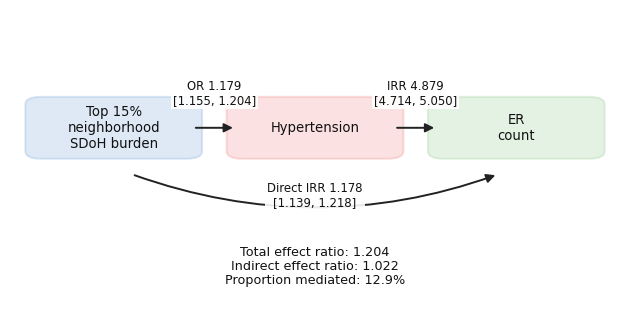

Saved mediation pathway figure: ../results/mediation/er_count_mediation_pathway_hypertension.png


In [23]:
er_mediation_plot_values = extract_mediation_plot_values(
    outcome_label="ER\ncount",
    mediator_coef_df=mediator_coef_df,
    outcome_coef_df=outcome_coef_df,
    mediation_summary=mediation_summary,
    exposure_col=EXPOSURE_COL,
    mediator_feature="hypertension"
)

plot_single_mediation_pathway(
    values=er_mediation_plot_values,
    save_dir=RESULTS_DIR,
    file_name="er_count_mediation_pathway_hypertension.png"
)

In [29]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# -----------------------------------
# Global font / paper-style settings
# -----------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 12
plt.rcParams["axes.linewidth"] = 1.0


def add_rect_box(ax, x, y, w, h, text, fontsize=16, weight="normal"):
    rect = Rectangle(
        (x, y), w, h,
        facecolor="white",
        edgecolor="black",
        linewidth=1.8
    )
    ax.add_patch(rect)
    ax.text(
        x + w / 2, y + h / 2,
        text,
        ha="center", va="center",
        fontsize=fontsize,
        fontweight=weight
    )


def add_straight_arrow(ax, start, end, color="black", lw=2.0):
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=lw,
        color=color,
        connectionstyle="arc3,rad=0"
    )
    ax.add_patch(arrow)


def plot_mediation_diagram(
    exposure_label,
    mediator_label,
    outcome_label,
    x_to_m_text,
    m_to_y_text,
    direct_text,
    total_text,
    indirect_text,
    prop_med_text,
    covariates_text,
    save_path=None,
    title=None
):
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # -----------------------------------
    # Box positions
    # -----------------------------------
    box_w = 0.24
    box_h = 0.13

    exp_x, exp_y = 0.08, 0.47
    med_x, med_y = 0.38, 0.20
    out_x, out_y = 0.68, 0.47

    # -----------------------------------
    # Draw boxes
    # -----------------------------------
    add_rect_box(ax, exp_x, exp_y, box_w, box_h, exposure_label, fontsize=16)
    add_rect_box(ax, med_x, med_y, box_w, box_h, mediator_label, fontsize=17, weight="bold")
    add_rect_box(ax, out_x, out_y, box_w, box_h, outcome_label, fontsize=16)

    # -----------------------------------
    # Direct arrow: Exposure -> Outcome
    # -----------------------------------
    add_straight_arrow(
        ax,
        (exp_x + box_w, exp_y + box_h / 2),
        (out_x, out_y + box_h / 2),
        color="black",
        lw=2.2
    )
    ax.text(
        0.50, 0.61,
        direct_text,
        ha="center", va="center",
        fontsize=14,
        color="black"
    )

    # -----------------------------------
    # Indirect arrow: Exposure -> Mediator
    # -----------------------------------
    add_straight_arrow(
        ax,
        (exp_x + box_w * 0.70, exp_y),
        (med_x + box_w * 0.25, med_y + box_h),
        color="#D9481C",
        lw=2.2
    )
    ax.text(
        0.30, 0.40,
        x_to_m_text,
        ha="center", va="center",
        fontsize=14,
        color="#D9481C"
    )

    # -----------------------------------
    # Indirect arrow: Mediator -> Outcome
    # -----------------------------------
    add_straight_arrow(
        ax,
        (med_x + box_w * 0.75, med_y + box_h),
        (out_x + box_w * 0.25, out_y),
        color="#D9481C",
        lw=2.2
    )
    ax.text(
        0.67, 0.40,
        m_to_y_text,
        ha="center", va="center",
        fontsize=14,
        color="#D9481C"
    )

    # -----------------------------------
    # Top bracket / total effect
    # -----------------------------------
    ax.plot([0.08, 0.08, 0.92, 0.92], [0.86, 0.91, 0.91, 0.86],
            color="#1F4E79", lw=2.3)
    ax.text(
        0.50, 0.915,
        total_text,
        ha="center", va="bottom",
        fontsize=16,
        color="#1F4E79",
        fontweight="bold"
    )

    # -----------------------------------
    # Indirect effect summary box
    # -----------------------------------
    summary_text = f"{indirect_text}\n{prop_med_text}"
    ax.text(
        0.50, 0.12,
        summary_text,
        ha="center", va="center",
        fontsize=14,
        bbox=dict(
            boxstyle="square,pad=0.35",
            facecolor="white",
            edgecolor="gray",
            linewidth=1.2
        )
    )

    # -----------------------------------
    # Title and footnote
    # -----------------------------------
    ax.text(
        0.00, 1.02,
        title,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=20,
        fontweight="bold"
    )

    ax.text(
        0.02, 0.01,
        covariates_text,
        ha="left", va="bottom",
        fontsize=12
    )

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")

    plt.show()

In [ ]:
# ============================================================
# PCP FULL COMORBIDITY FIGURE
# ============================================================
plot_mediation_diagram(
    exposure_label="Top 15% neighborhood\nnSDoH burden",
    mediator_label="Hypertension",
    outcome_label="PCP count",
    x_to_m_text="OR = 1.270\n[1.244, 1.296]",
    m_to_y_text="IRR = 4.218\n[4.156, 4.280]",
    direct_text="Direct effect ratio = 1.040\n[1.026, 1.054]",
    total_text="Total effect ratio = 1.070",
    indirect_text="Indirect effect ratio = 1.029",
    prop_med_text="Proportion mediated = 43.3%",
    covariates_text="Adjusted for age ≥65, sex, race, and baseline comorbidity burden excluding hypertension."
)

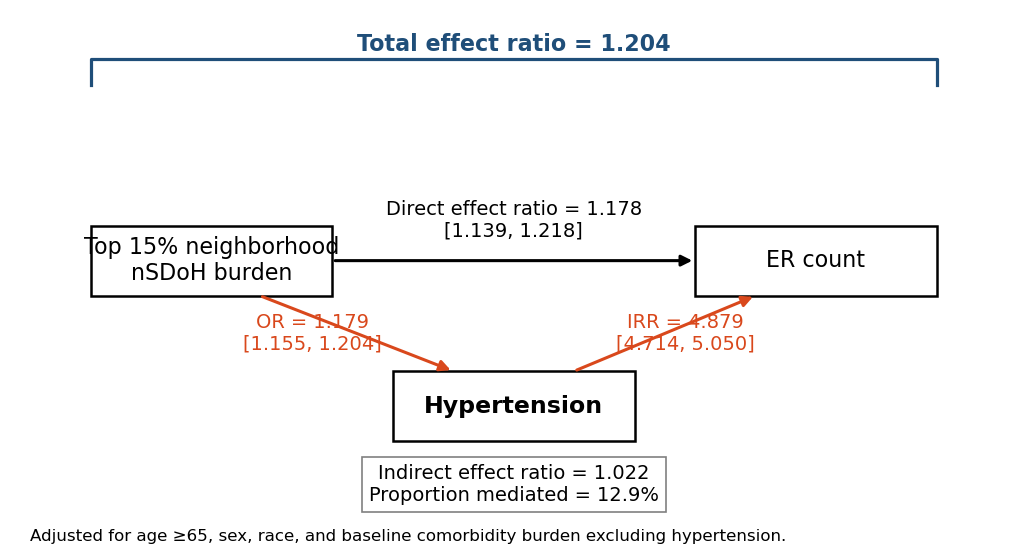

In [30]:
# ============================================================
# ER FULL COMORBIDITY FIGURE
# ============================================================
plot_mediation_diagram(
    exposure_label="Top 15% neighborhood\nnSDoH burden",
    mediator_label="Hypertension",
    outcome_label="ER count",
    x_to_m_text="OR = 1.179\n[1.155, 1.204]",
    m_to_y_text="IRR = 4.879\n[4.714, 5.050]",
    direct_text="Direct effect ratio = 1.178\n[1.139, 1.218]",
    total_text="Total effect ratio = 1.204",
    indirect_text="Indirect effect ratio = 1.022",
    prop_med_text="Proportion mediated = 12.9%",
    covariates_text="Adjusted for age ≥65, sex, race, and baseline comorbidity burden excluding hypertension."
)

In [37]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# --------------------------------------------------
# Global paper-style settings
# --------------------------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 12
plt.rcParams["axes.linewidth"] = 1.0


def draw_box(ax, x, y, w, h, text, fontsize=15, weight="normal"):
    box = Rectangle(
        (x, y), w, h,
        linewidth=1.6,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=fontsize,
        fontweight=weight
    )


def draw_arrow(ax, start, end, color="black", lw=2.0, rad=0):
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=lw,
        color=color,
        connectionstyle=f"arc3,rad={rad}"
    )
    ax.add_patch(arrow)


def plot_publication_mediation_figure(
    panel_label="A",
    outcome_name="PCP count",
    exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
    mediator_label="Hypertension",
    outcome_label="PCP count",
    total_effect_text="Total effect ratio = 1.070",
    direct_effect_text="Direct effect ratio = 1.040\n[1.026, 1.054]",
    exposure_to_mediator_text="OR = 1.270\n[1.244, 1.296]",
    mediator_to_outcome_text="IRR = 4.218\n[4.156, 4.280]",
    indirect_effect_text="Indirect effect ratio = 1.029",
    proportion_text="Total effect mediated = 43.3%",
    footnote_text="Adjusted for age ≥65, sex, race, and baseline comorbidity burden excluding hypertension.",
    save_path=None
):
    # Figure canvas
    fig, ax = plt.subplots(figsize=(10.5, 4.2))
    ax.set_xlim(0.04, 0.96)
    ax.set_ylim(0.12, 0.84)
    ax.axis("off")
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    # Colors
    main_color = "black"
    indirect_color = "#D9481C"   # orange-red
    total_color = "#1F4E79"      # dark blue

    # Panel label
#     ax.text(0.00, 1.02, panel_label, transform=ax.transAxes,
#             fontsize=20, fontweight="bold", ha="left", va="bottom")

    # Optional small subtitle
#     ax.text(0.06, 1.02, f"Mediation model: {outcome_name}",
#             transform=ax.transAxes, fontsize=17, ha="left", va="bottom")

    # Box positions
    box_w = 0.24
    box_h = 0.12

    x_exp, y_exp = 0.08, 0.50
    x_med, y_med = 0.38, 0.18
    x_out, y_out = 0.68, 0.50

    # Draw boxes
    draw_box(ax, x_exp, y_exp, box_w, box_h, exposure_label, fontsize=15)
    draw_box(ax, x_med, y_med, box_w, box_h, mediator_label, fontsize=16, weight="bold")
    draw_box(ax, x_out, y_out, box_w, box_h, outcome_label, fontsize=15)

    # Direct path: Exposure -> Outcome
    draw_arrow(
        ax,
        (x_exp + box_w, y_exp + box_h/2),
        (x_out, y_out + box_h/2),
        color=main_color, lw=2.2
    )
    ax.text(
        0.50, 0.64,
        direct_effect_text,
        ha="center", va="center",
        fontsize=14,
        color=main_color
    )

    # Indirect path: Exposure -> Mediator
    draw_arrow(
        ax,
        (x_exp + box_w*0.60, y_exp),
        (x_med + box_w*0.30, y_med + box_h),
        color=indirect_color, lw=2.2, rad=-0.05
    )
    ax.text(
        0.25, 0.42,
        exposure_to_mediator_text,
        ha="center", va="center",
        fontsize=13,
        color=indirect_color,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.2)
    )

    # Indirect path: Mediator -> Outcome
    draw_arrow(
        ax,
        (x_med + box_w*0.70, y_med + box_h),
        (x_out + box_w*0.25, y_out),
        color=indirect_color, lw=2.2, rad=0.05
    )
    ax.text(
        0.69, 0.42,
        mediator_to_outcome_text,
        ha="center", va="center",
        fontsize=13,
        color=indirect_color,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.2)
    )

    # Total effect bracket
    ax.plot([0.08, 0.08, 0.92, 0.92],
            [0.73, 0.78, 0.78, 0.73],
            color=total_color, lw=2.4)
    ax.text(
        0.50, 0.785,
        total_effect_text,
        ha="center", va="bottom",
        fontsize=16,
        color=total_color,
        fontweight="bold"
    )
    ax.text(
        0.50, 0.765,
        proportion_text,
        ha="center", va="top",
        fontsize=16,
        color=total_color,
        fontweight="bold"
    )

    # Bottom summary box
#     summary_text = f"{indirect_effect_text}\n{proportion_text}"
#     ax.text(
#         0.50, 0.09,
#         summary_text,
#         ha="center", va="center",
#         fontsize=14,
#         bbox=dict(
#             boxstyle="square,pad=0.35",
#             facecolor="white",
#             edgecolor="gray",
#             linewidth=1.2
#         )
#     )

    # Footnote
#     ax.text(
#         0.02, 0.01,
#         footnote_text,
#         ha="left", va="bottom",
#         fontsize=11
#     )

#     plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
        # Optional: save vector versions for paper
        base = save_path.rsplit(".", 1)[0]
        plt.savefig(base + ".pdf", bbox_inches="tight", facecolor="white")
        plt.savefig(base + ".svg", bbox_inches="tight", facecolor="white")

    plt.show()

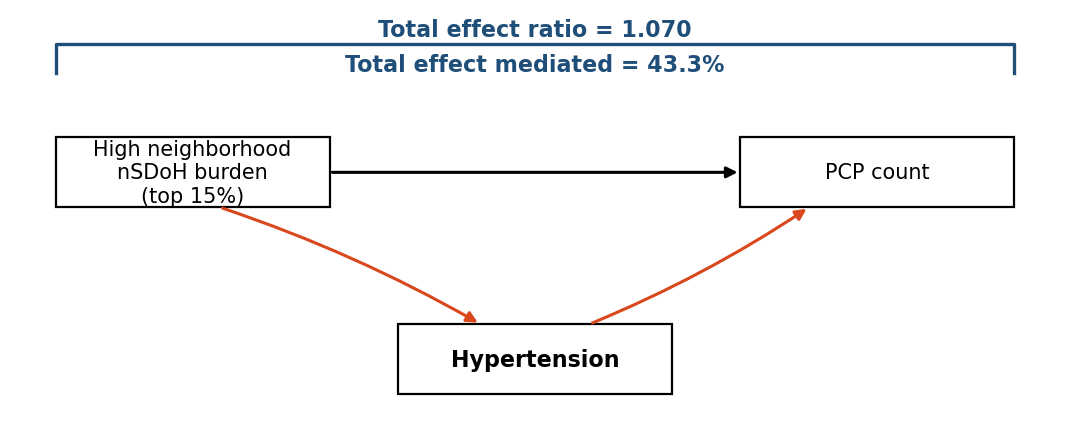

In [39]:
plot_publication_mediation_figure(
    panel_label="A",
    outcome_name="PCP count",
    exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
    mediator_label="Hypertension",
    outcome_label="PCP count",
    total_effect_text="Total effect ratio = 1.070",
    direct_effect_text="",
    exposure_to_mediator_text="",
    mediator_to_outcome_text="",
    indirect_effect_text="",
    proportion_text="Total effect mediated = 43.3%",
    footnote_text="",
    save_path="mediation_pcp_conceptual.png"
)

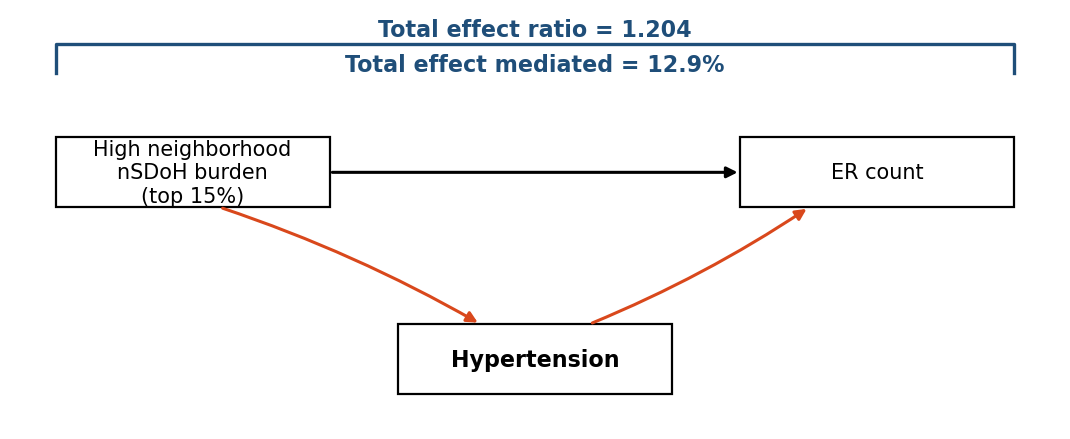

In [40]:
plot_publication_mediation_figure(
    panel_label="B",
    outcome_name="ER count",
    exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
    mediator_label="Hypertension",
    outcome_label="ER count",
    total_effect_text="Total effect ratio = 1.204",
    direct_effect_text="",
    exposure_to_mediator_text="",
    mediator_to_outcome_text="",
    indirect_effect_text="",
    proportion_text="Total effect mediated = 12.9%",
    footnote_text="",
    save_path="mediation_er_conceptual.png"
)

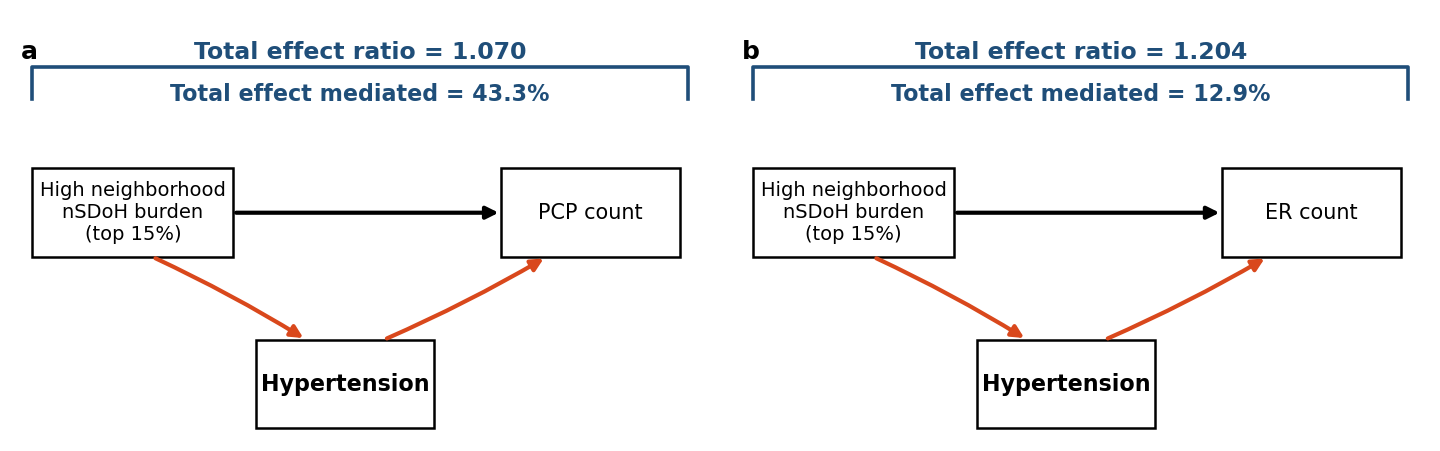

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# --------------------------------------------------
# Global paper-style settings
# --------------------------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 13
plt.rcParams["axes.linewidth"] = 1.0


def draw_box(ax, x, y, w, h, text, fontsize=16, weight="normal"):
    box = Rectangle(
        (x, y), w, h,
        linewidth=1.8,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=fontsize,
        fontweight=weight
    )


def draw_arrow(ax, start, end, color="black", lw=2.8, rad=0):
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=lw,
        color=color,
        connectionstyle=f"arc3,rad={rad}"
    )
    ax.add_patch(arrow)


def draw_mediation_panel(
    ax,
    panel_label="a",
    exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
    mediator_label="Hypertension",
    outcome_label="PCP count",
    total_effect_text="Total effect ratio = 1.070",
    proportion_text="Total effect mediated = 43.3%"
):
    ax.set_xlim(0.03, 0.97)
    ax.set_ylim(0.14, 0.82)
    ax.axis("off")

    # Colors
    main_color = "black"
    indirect_color = "#D9481C"
    total_color = "#1F4E79"

    # Panel label: bring a/b a little down
    ax.text(
        0.015, 0.93, panel_label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=18,
        fontweight="bold"
    )

    # Box sizes
    exp_w = 0.27     # wider so text fits
    med_w = 0.24
    out_w = 0.24
    box_h = 0.14

    # Box positions
    x_exp, y_exp = 0.06, 0.43
    x_med, y_med = 0.36, 0.16
    x_out, y_out = 0.69, 0.43

    # Draw boxes
    draw_box(ax, x_exp, y_exp, exp_w, box_h, exposure_label, fontsize=14)
    draw_box(ax, x_med, y_med, med_w, box_h, mediator_label, fontsize=16, weight="bold")
    draw_box(ax, x_out, y_out, out_w, box_h, outcome_label, fontsize=15)

    # Direct path
    draw_arrow(
        ax,
        (x_exp + exp_w, y_exp + box_h/2),
        (x_out, y_out + box_h/2),
        color=main_color, lw=3.0
    )

    # Exposure -> Mediator
    draw_arrow(
        ax,
        (x_exp + exp_w*0.60, y_exp),
        (x_med + med_w*0.28, y_med + box_h),
        color=indirect_color, lw=3.0, rad=-0.03
    )

    # Mediator -> Outcome
    draw_arrow(
        ax,
        (x_med + med_w*0.72, y_med + box_h),
        (x_out + out_w*0.25, y_out),
        color=indirect_color, lw=3.0, rad=0.03
    )

    # Top bracket: bring closer to main figure
    ax.plot(
        [0.06, 0.06, 0.94, 0.94],
        [0.68, 0.73, 0.73, 0.68],
        color=total_color,
        lw=2.6
    )

    ax.text(
        0.50, 0.735,
        total_effect_text,
        ha="center", va="bottom",
        fontsize=17,
        color=total_color,
        fontweight="bold"
    )

    ax.text(
        0.50, 0.705,
        proportion_text,
        ha="center", va="top",
        fontsize=16,
        color=total_color,
        fontweight="bold"
    )

def plot_combined_mediation_figure(save_path="mediation_combined.png"):
    fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.9))

    # reduce distance between two figures
    fig.subplots_adjust(
        left=0.02,
        right=0.98,
        top=0.96,
        bottom=0.08,
        wspace=0.03
    )

    draw_mediation_panel(
        ax=axes[0],
        panel_label="a",
        exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
        mediator_label="Hypertension",
        outcome_label="PCP count",
        total_effect_text="Total effect ratio = 1.070",
        proportion_text="Total effect mediated = 43.3%"
    )

    draw_mediation_panel(
        ax=axes[1],
        panel_label="b",
        exposure_label="High neighborhood\nnSDoH burden\n(top 15%)",
        mediator_label="Hypertension",
        outcome_label="ER count",
        total_effect_text="Total effect ratio = 1.204",
        proportion_text="Total effect mediated = 12.9%"
    )

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
        base = save_path.rsplit(".", 1)[0]
        plt.savefig(base + ".pdf", bbox_inches="tight", facecolor="white")
        plt.savefig(base + ".svg", bbox_inches="tight", facecolor="white")

    plt.show()


plot_combined_mediation_figure(save_path="mediation_combined.png")